# 02 — Pipeline TDA con datos reales (CBIS-DDSM)

Entorno de trabajo interactivo sobre el pipeline real (no sintético). Reutiliza
exactamente el mismo código que `scripts/run_pipeline.py`, `scripts/train_cnn.py`
y `scripts/fuse_and_evaluate.py` — este notebook es para explorar/depurar celda
a celda, los scripts son para reproducir resultados de un tirón.

**Requisito previo:** haber descargado los CSV reales (`data/csv/`) y al menos
un piloto de imágenes (`python scripts/download_cbis_ddsm.py --add 15 15`).


## 0. Configuración e imports

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "scripts"))

from src.data import load_case_descriptions, split_by_patient
from src.preprocessing import preprocess
from src.topology import backend, persistence_diagram, persistence_image_vector
from src.evaluate import clinical_metrics, plot_confusion, plot_persistence_diagram
from src.models import build_random_forest, build_svm

import run_pipeline as rp  # funciones compartidas: _load_case_images, build_dataset

print("Backend TDA activo:", backend())


Backend TDA activo: gudhi


## 1. Metadatos reales

Carga los 4 CSV de CBIS-DDSM (con la etiqueta benigno/maligno real) y particiona
por paciente (nunca por imagen, para no repetir la fuga de datos del
`Demo_Notebook.ipynb` original).

In [2]:
df = load_case_descriptions(ROOT / "data" / "csv")
df_mass = df[df["_prefix"].str.startswith("Mass")].reset_index(drop=True)
print(f"{len(df_mass)} filas de casos de masa, {df_mass['patient_id'].nunique()} pacientes únicos")
df_mass["pathology"].value_counts()


1696 filas de casos de masa, 892 pacientes únicos


pathology
MALIGNANT                  784
BENIGN                     771
BENIGN_WITHOUT_CALLBACK    141
Name: count, dtype: int64

In [3]:
partitions = split_by_patient(df_mass)
for name, part in partitions.items():
    print(f"{name}: {len(part)} filas, {part['patient_id'].nunique()} pacientes")


train: 1181 filas, 624 pacientes
val: 260 filas, 134 pacientes
test: 255 filas, 134 pacientes


## 2. Cargar y previsualizar un caso real

`rp._load_case_images(row)` ya sabe reconstruir el nombre de carpeta real de TCIA
y distinguir la máscara ROI del recorte pre-hecho (ver nota en
`scripts/download_cbis_ddsm.py:download_case`). Devuelve `None` si ese caso
concreto aún no se ha descargado.

Caso: P_00158 (RIGHT MLO), pathology=BENIGN_WITHOUT_CALLBACK


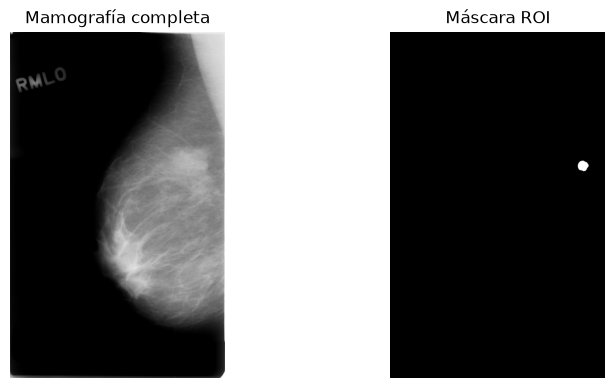

In [4]:
ejemplo = None
for _, row in df_mass.iterrows():
    loaded = rp._load_case_images(row)
    if loaded is not None:
        ejemplo = (row, *loaded)
        break

if ejemplo is None:
    print("Ningún caso descargado todavía — amplía el piloto con scripts/download_cbis_ddsm.py")
else:
    row, full_image, mask = ejemplo
    print(f"Caso: {row['patient_id']} ({row['left_or_right_breast']} {row['image_view']}), "
          f"pathology={row['pathology']}")

    fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
    axes[0].imshow(full_image, cmap="gray"); axes[0].set_title("Mamografía completa"); axes[0].axis("off")
    if mask is not None:
        axes[1].imshow(mask, cmap="gray"); axes[1].set_title("Máscara ROI")
    else:
        axes[1].text(0.5, 0.5, "sin máscara\n(caso raro, ver nota)", ha="center")
    axes[1].axis("off")
    plt.show()


## 3. Preprocesado + descriptor topológico de ese mismo caso

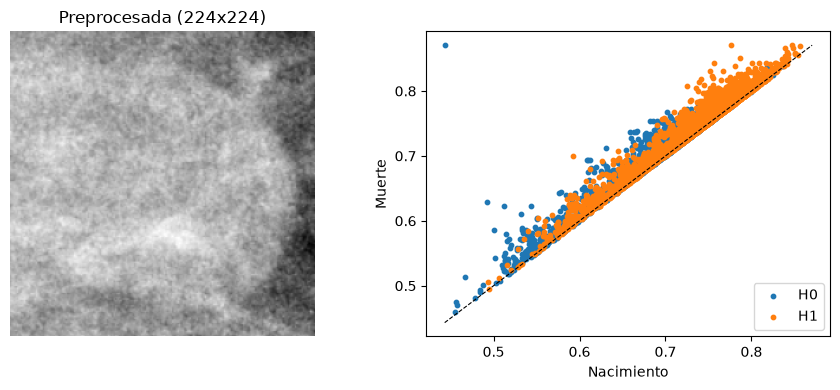

Vector de features (n_bins=4): (1, 32)


In [5]:
if ejemplo is not None:
    img_pp = preprocess(full_image, mask=mask)
    diagrama = persistence_diagram(img_pp)
    vector = persistence_image_vector(diagrama, n_bins=4)

    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    axes[0].imshow(img_pp, cmap="gray"); axes[0].set_title("Preprocesada (224x224)"); axes[0].axis("off")
    plot_persistence_diagram(diagrama, ax=axes[1])
    plt.tight_layout(); plt.show()

    print("Vector de features (n_bins=4):", vector.shape)


## 4. Dataset completo (todos los casos ya descargados)

Usa `rp.build_dataset`, la misma función que `scripts/run_pipeline.py`: recorre
el DataFrame, carga cada imagen disponible, preprocesa y extrae el vector
topológico. Los casos sin imagen descargada se omiten (y se cuentan).

In [6]:
X_train, y_train, _ = rp.build_dataset(partitions["train"], n_bins=4)
X_test, y_test, test_rows = rp.build_dataset(partitions["test"], n_bins=4)

print(f"Usables: {len(X_train)} train, {len(X_test)} test")
print("Balance train:", np.bincount(y_train), " | Balance test:", np.bincount(y_test))


  (1141 casos del CSV omitidos: imagenes no descargadas todavia)


  (247 casos del CSV omitidos: imagenes no descargadas todavia)
Usables: 40 train, 8 test
Balance train: [29 11]  | Balance test: [2 6]


## 5. Clasificador topológico + métricas clínicas

accuracy: 0.000
sensibilidad_recall: 0.000
especificidad: 0.000
precision: 0.000
f1: 0.000
auc: 0.000


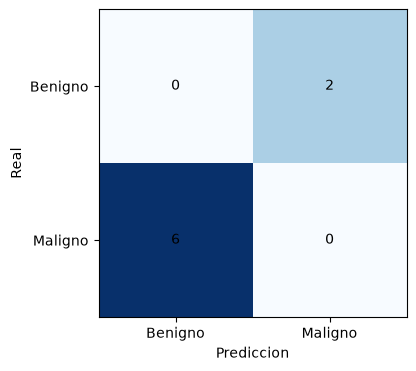

In [7]:
if len(X_train) and len(X_test):
    clf = build_random_forest()
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    y_score = clf.predict_proba(X_test)[:, 1]

    metrics = clinical_metrics(y_test, y_pred, y_score=y_score)
    for k, v in metrics.items():
        print(f"{k}: {v:.3f}")

    plot_confusion(y_test, y_pred)
    plt.show()
else:
    print("Amplía el piloto antes de entrenar: python scripts/download_cbis_ddsm.py --add 15 15")


## 6. Validación por CV (más fiable que el test único)

Con pilotos pequeños, el AUC de un solo split de test es ruidoso (se observó
variar entre 0.4 y 0.65 solo por el tamaño de muestra). La media de validación
cruzada sobre train es una estimación más estable.

In [8]:
from sklearn.model_selection import cross_val_score

if len(X_train) >= 10:
    cv_auc = cross_val_score(build_random_forest(), X_train, y_train, cv=5, scoring="roc_auc")
    print(f"AUC (5-fold CV sobre train): {cv_auc.mean():.3f} +/- {cv_auc.std():.3f}")


AUC (5-fold CV sobre train): 0.850 +/- 0.143


## 7. CNN de referencia + fusión (opcional, más lento)

Reutiliza `scripts/train_cnn.py` (PyTorch, DenseNet121, semilla fija). Puede
tardar unos minutos en CPU.

In [9]:
import train_cnn as tc

X_img_train, y_img_train = tc.build_image_dataset(partitions["train"])
X_img_test, y_img_test = tc.build_image_dataset(partitions["test"])

if len(X_img_train):
    model, device = tc.train_cnn(X_img_train, y_img_train, epochs=10, lr=1e-4, batch_size=8)
    y_pred_cnn, y_score_cnn = tc.evaluate_cnn(model, device, X_img_test, y_img_test)
    print(clinical_metrics(y_img_test, y_pred_cnn, y_score=y_score_cnn))


  (1141 casos del CSV omitidos: imagenes no descargadas todavia)


  (247 casos del CSV omitidos: imagenes no descargadas todavia)


  epoch 1/10  loss=0.7383


  epoch 2/10  loss=0.5723


  epoch 3/10  loss=0.6640


  epoch 4/10  loss=0.6164


... (2 outputs left out)

  epoch 7/10  loss=0.6320


  epoch 8/10  loss=0.4890


  epoch 9/10  loss=0.6600


  epoch 10/10  loss=0.5667
{'accuracy': 0.25, 'sensibilidad_recall': 0.3333333333333333, 'especificidad': np.float64(0.0), 'precision': 0.5, 'f1': 0.4, 'auc': 0.0}


## 8. Hipótesis longitudinal: validación sintética

Mientras se gestiona el acceso a un dataset longitudinal real (CSAW-CC/EMBED,
ver issue `#92`), esta celda reutiliza
`scripts/synthetic_longitudinal_validation.py` para comprobar que el pipeline
mide señal de anticipación cuando existe.

In [10]:
import synthetic_longitudinal_validation as slv

resultado = slv.run_experiment(n_per_class=60, n_bins=6, seed=42)
for k, v in resultado.items():
    print(f"{k}: {v:.3f}")


auc_anticipacion: 0.871
std_anticipacion: 0.089
auc_deriva: 0.937
std_deriva: 0.063
auc_combinada: 0.924
std_combinada: 0.055


## Siguientes pasos

- Ampliar el piloto: `python scripts/download_cbis_ddsm.py --add 15 15`
- Barrido de sensibilidad longitudinal: `python scripts/synthetic_longitudinal_validation.py --sweep`
- Ver el estado de la investigación y las decisiones tomadas en los issues de GitHub (`F0'`).
